#  Yield Curve & Spread Analysis (US)

## Goal
We use FRED data to study the US yield curve and key spreads (2s10s, 3m10y), and connect:
- **curve inversions** → **recession risk**
- **inflation dynamics** → **policy expectations** → **curve shape**

This notebook is structured as follows:
1. Load data from FRED  
2. Time series  
3. Build spreads and visualize regime changes  
4. Overlay recessions and interpret inversions  
5. Relate curve dynamics to inflation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas_datareader import data as pdr


from fredapi import Fred

fred = Fred(api_key="")  #use your API key here!

# Plot defaults (keep it simple and consistent)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

##  Download data from FRED

Treasury yields are available daily but have missing values on weekends/holidays.
CPI is monthly.
The recession indicator is monthly (0/1), but FRED returns it as a daily/periodic series aligned by date.

We will:
- download everything into one DataFrame
- forward-fill yields (only yields) to handle missing business days
- keep CPI and recession indicator as-is (then align later)

In [5]:
start = "1990-01-01"

series = {
    "3M": "DGS3MO",
    "2Y": "DGS2",
    "10Y": "DGS10",
    "CPI": "CPIAUCSL",
    "REC": "USREC",
}

# Download series one by one as Series, then align by date index
data = {}
for name, code in series.items():
    tmp = pdr.DataReader(code, "fred", start)  # one-column DataFrame
    data[name] = tmp.iloc[:, 0]                # take the single column as a Series

df = pd.concat(data, axis=1)
df.tail()

,3M,2Y,10Y,CPI,REC
DATE,,,,,
2026-01-23,3.70,3.60,4.24,NaN,NaN
2026-01-26,3.67,3.56,4.22,NaN,NaN
2026-01-27,3.67,3.53,4.24,NaN,NaN
2026-01-28,3.68,3.56,4.26,NaN,NaN
2026-01-29,3.67,3.53,4.24,NaN,NaN


In [7]:
# Forward fill yields only (weekends/holidays)
df[["3M", "2Y", "10Y"]] = df[["3M", "2Y", "10Y"]].ffill()

# Drop rows that still have missing values (mostly early CPI alignment issues)
df = df.dropna()

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 430 entries, 1990-02-01 to 2025-12-01
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   3M      430 non-null    float64
 1   2Y      430 non-null    float64
 2   10Y     430 non-null    float64
 3   CPI     430 non-null    float64
 4   REC     430 non-null    float64
dtypes: float64(5)
memory usage: 20.2 KB


## Visualize the yield curve

First, we plot the three yields (3M, 2Y, 10Y).
This reveals:
- long-run yield regimes
- tightening / easing cycles
- whether the curve is “normal” (upward sloping) or inverted

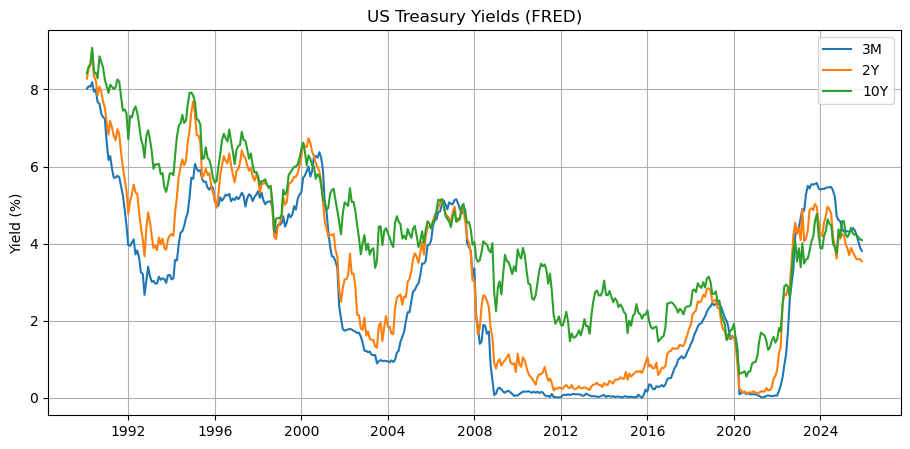

In [12]:
fig, ax = plt.subplots()

ax.plot(df.index, df["3M"], label="3M")
ax.plot(df.index, df["2Y"], label="2Y")
ax.plot(df.index, df["10Y"], label="10Y")

ax.set_title("US Treasury Yields (FRED)")
ax.set_ylabel("Yield (%)")
ax.legend()

plt.show()

##  Build yield spreads

We focus on two classic spreads:

- **2s10s** = 10Y − 2Y  
  Captures medium/long-term growth expectations vs policy expectations.

- **3m10y** = 10Y − 3M  
  Often considered a strong “policy vs long-term” signal and historically famous as a recession indicator.

Interpretation:
- Spread > 0 → normal curve  
- Spread < 0 → inversion (markets expect future rate cuts / slowdown)

In [15]:
df["2s10s"] = df["10Y"] - df["2Y"]
df["3m10y"] = df["10Y"] - df["3M"]

df[["2s10s", "3m10y"]].describe()

,2s10s,3m10y
count,430.000000,430.000000
mean,1.009186,1.452419
std,0.915830,1.282383
min,-1.060000,-1.890000
25%,0.242500,0.512500
50%,0.905000,1.480000
75%,1.807500,2.500000
max,2.870000,3.840000


## Spreads over time and inversion episodes

We plot spreads and highlight the **zero line**.
Whenever the line goes below zero, the curve is inverted.

This is where we start asking:
- how long do inversions last?
- do they cluster before recessions?

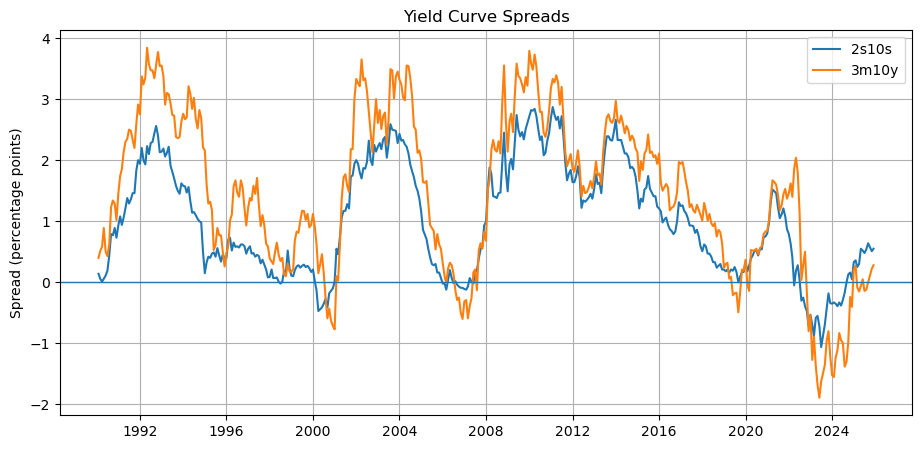

In [18]:
fig, ax = plt.subplots()

ax.plot(df.index, df["2s10s"], label="2s10s")
ax.plot(df.index, df["3m10y"], label="3m10y")

ax.axhline(0, linewidth=1)  # zero line = inversion threshold

ax.set_title("Yield Curve Spreads")
ax.set_ylabel("Spread (percentage points)")
ax.legend()

plt.show()

## Spreads and recessions (NBER shading)

Now we overlay the NBER recession indicator (`USREC`).

Goal:
- visually check whether inversions tend to appear **before** recessions
- compare 2s10s vs 3m10y behavior around recessions

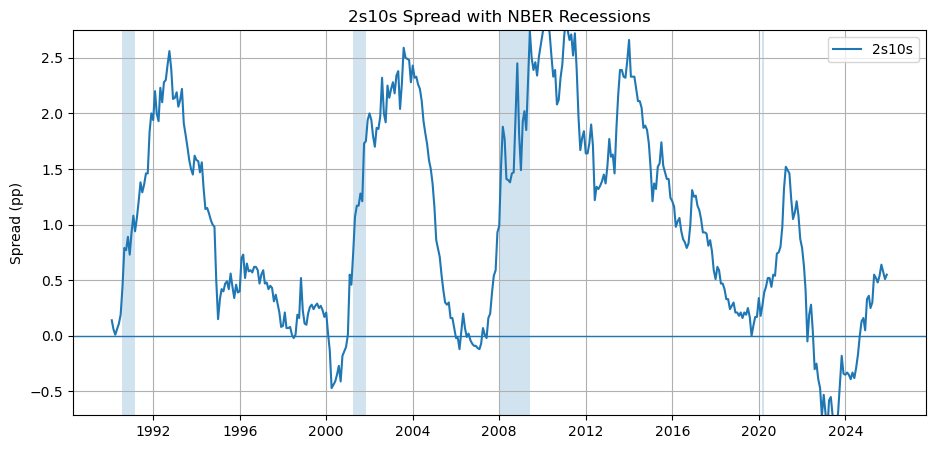

In [21]:
def shade_recessions(ax, dates, rec_series):
    """Shade recession periods where rec_series == 1."""
    rec = rec_series == 1
    ax.fill_between(dates, ax.get_ylim()[0], ax.get_ylim()[1], where=rec, alpha=0.2)

# 2s10s with recession shading
fig, ax = plt.subplots()
ax.plot(df.index, df["2s10s"], label="2s10s")
ax.axhline(0, linewidth=1)
ax.set_title("2s10s Spread with NBER Recessions")
ax.set_ylabel("Spread (pp)")

# Important: set y-limits before shading so the shading fills the plot area
ax.set_ylim(df["2s10s"].quantile(0.01), df["2s10s"].quantile(0.99))
shade_recessions(ax, df.index, df["REC"])

ax.legend()
plt.show()

## Inflation vs yield curve

We compute **CPI YoY inflation** and compare it with spreads.

Intuition:
- rising inflation → central bank likely tightens → curve flattens
- when markets expect future growth weakness → long yields stop rising → inversion can appear

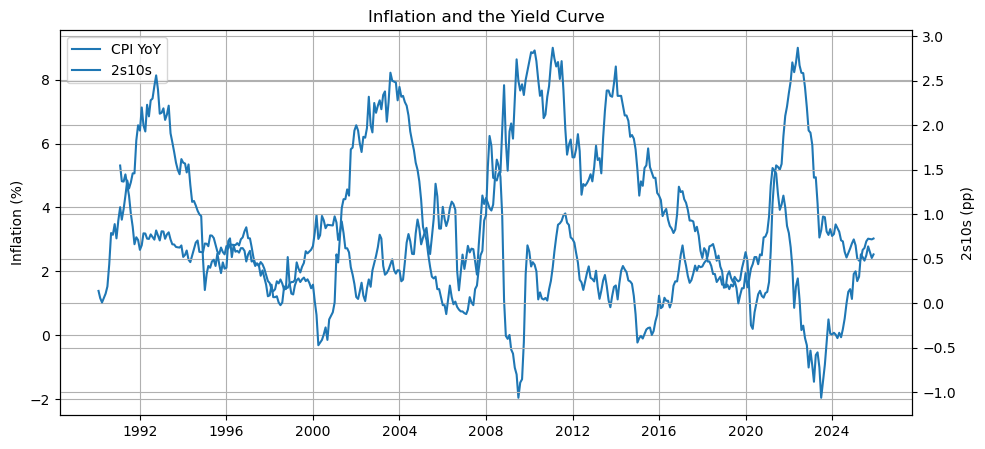

In [24]:
# CPI YoY inflation (monthly series; YoY works naturally on monthly data)
df["CPI_YoY"] = df["CPI"].pct_change(12) * 100

fig, ax1 = plt.subplots()

ax1.plot(df.index, df["CPI_YoY"], label="CPI YoY")
ax1.set_ylabel("Inflation (%)")
ax1.set_title("Inflation and the Yield Curve")

ax2 = ax1.twinx()
ax2.plot(df.index, df["2s10s"], label="2s10s")
ax2.set_ylabel("2s10s (pp)")

# Combine legends cleanly
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.show()